# The v1 tariff and rating engine: summary

This notebook shows the v1 tariff that the rating engine and the pricing service use. It loads the tables saved in `outputs/v1/` and
never fits a model. The quotes come from the rating engine, which reads the same tables. It runs in a few seconds.

The premium for a profile is

$$\text{premium} = \text{base rate} \times \prod_{f} r_{f,\ell_f} \times s, \qquad
\text{base rate} = b_{2022} \times \tau \times \rho,$$

where $r_{f,\ell_f}$ is the relativity of the profile's level $\ell_f$ of rating factor $f$ (age band, region and the seven condition
flags), $b_{2022}$ is the base rate at the 2022 level, $\tau$ is the forecast trend of 1.019 and $\rho$ is the decided rebase of 1.06. The
scaling $s$ turns dollars into a **risk premium (expected claims cost), illustrative £**, which excludes expenses and margin. The
dollar premium has $s = 1$.

**Summary.** The tariff is a multiplicative surrogate of the technical model, fitted on 2022 data. The adult age relativities follow a
monotone rule, so a premium never falls with age. The rating engine and the golden cases reproduce the tariff exactly. A rate change
is tested on an aggregated in-force book.

### Headline numbers from the saved tables

The table is read from the files named in its last column.

In [1]:
import pandas as pd
from IPython.display import Image

from health_pricing import tariff_summary

pd.options.display.max_colwidth = None
tariff_summary.headline_numbers()

,number,value,source
0,"Test deviance, 2022 split","839,170",model_version.json
1,"Test Gini, 2022 split",0.376,model_version.json
2,"Out-of-fold deviance, grouped CV","3,085,067",model_version.json
3,"Out-of-fold Gini, grouped CV",0.476,model_version.json
4,A/E on 2023 at the rating-period level,1.080,model_version.json
5,Base rate at 2022 level (dollars),"1,828",base_rate.csv
6,Rating-period level factor,1.080,model_version.json
7,Base rate at the rating-period level (dollars),"1,975",base_rate.csv
8,"Scaling, pounds per dollar",0.244,scaling.json
9,UK claims cost per covered life (pounds),576,scaling.json


## The relativities

Each row is the relativity of one level against the reference level of its factor (a relativity of 1 and no bounds for the reference).
Age is shown against the 65-69 band as fitted before the rule, which the base rate carries. The bounds keep the width of the technical
model's combined bounds (frequency and severity treated as independent), centred on the tariff relativity. They show model uncertainty.
The bounds are not a fit of the tariff. The 65-69 band has none, because the model measures age against it.

In [2]:
tariff_summary.relativity_table()

,factor,level,relativity,exposure,lower_95,upper_95
0,age,05-14,0.231,2002,0.164,0.325
1,age,00-04,0.300,693,0.177,0.509
2,age,15-17,0.459,634,0.289,0.728
3,age,18-24,0.299,1169,0.205,0.438
4,age,25-29,0.432,945,0.292,0.637
5,age,30-34,0.553,1020,0.389,0.785
6,age,35-39,0.667,1116,0.477,0.932
7,age,40-44,0.742,1046,0.537,1.024
8,age,45-49,0.781,994,0.570,1.071
9,age,50-54,0.825,1127,0.619,1.099


## The age curve before and after the monotone rule

The rule pools the adult bands from 60-64 to 80+ to one relativity of 0.963, because the fitted tariff falls after 65-69. The base rate
is then rebalanced so total predicted cost on 2022 train is unchanged (a multiplier of 0.998). Children and the adult bands below 60-64
are unchanged. The saved table of the draft in `outputs/m6_draft/` holds the values before the rule, and `published` is the value in
`outputs/v1/relativities.csv`.

In [3]:
tariff_summary.age_before_after().round(3)

,age_band,relativity_before,relativity_after,published,change_pct
0,00-04,0.300,0.300,0.300,0.000
1,05-14,0.231,0.231,0.231,0.000
2,15-17,0.459,0.459,0.459,0.000
3,18-24,0.299,0.299,0.299,0.000
4,25-29,0.432,0.432,0.432,0.000
5,30-34,0.553,0.553,0.553,0.000
6,35-39,0.667,0.667,0.667,0.000
7,40-44,0.742,0.742,0.742,0.000
8,45-49,0.781,0.781,0.781,0.000
9,50-54,0.825,0.825,0.825,0.000


In [4]:
tariff_summary.age_curve_figure()

<Figure size 800x400 with 1 Axes>

## Example quotes from the rating engine

Four golden cases, priced by `health_pricing.rating.rate` from the published tables. The last column checks each premium against the
expected premium in `golden_cases.csv`. The golden cases are a **regression baseline, provisional until the Excel reconciliation**, which
will replace them.

In [5]:
quotes = tariff_summary.example_quotes()
tariff_summary.quote_summary(quotes)

,case,age,region,conditions,premium_usd,risk_premium_gbp_illustrative,matches_golden_case
0,reference profile at age 40,40,3,0,1465.01,357.46,True
1,child with asthma,8,1,1,671.25,163.79,True
2,senior with three conditions,72,2,3,5785.35,1411.63,True
3,all conditions at age 55,55,3,7,12435.48,3034.26,True


**Reference profile at age 40.** No conditions, region 3.

In [6]:
tariff_summary.breakdown(quotes["reference profile at age 40"])

,step,level,factor,running_premium
0,base rate at 2022 level,,1828.2547,1828.25
1,age,40-44,0.7419,1356.32
2,region,3,1.0000,1356.32
3,HIBPDX,0,1.0000,1356.32
4,CHDDX,0,1.0000,1356.32
5,OHRTDX,0,1.0000,1356.32
6,CHOLDX,0,1.0000,1356.32
7,CANCERDX,0,1.0000,1356.32
8,ARTHDX,0,1.0000,1356.32
9,ASTHDX,0,1.0000,1356.32


**Child with asthma.** Age 8, region 1.

In [7]:
tariff_summary.breakdown(quotes["child with asthma"])

,step,level,factor,running_premium
0,base rate at 2022 level,,1828.2547,1828.25
1,age,05-14,0.2310,422.26
2,region,1,1.1524,486.61
3,HIBPDX,0,1.0000,486.61
4,CHDDX,0,1.0000,486.61
5,OHRTDX,0,1.0000,486.61
6,CHOLDX,0,1.0000,486.61
7,CANCERDX,0,1.0000,486.61
8,ARTHDX,0,1.0000,486.61
9,ASTHDX,1,1.2771,621.45


**Senior with three conditions.** Age 72, region 2, heart disease, arthritis and high blood pressure.

In [8]:
tariff_summary.breakdown(quotes["senior with three conditions"])

,step,level,factor,running_premium
0,base rate at 2022 level,,1828.2547,1828.25
1,age,70-74,0.9625,1759.76
2,region,2,1.1869,2088.60
3,HIBPDX,1,1.1083,2314.82
4,CHDDX,1,1.3824,3199.91
5,OHRTDX,0,1.0000,3199.91
6,CHOLDX,0,1.0000,3199.91
7,CANCERDX,0,1.0000,3199.91
8,ARTHDX,1,1.6738,5356.11
9,ASTHDX,0,1.0000,5356.11


**All conditions at age 55.** Region 3, with all seven condition flags.

In [9]:
tariff_summary.breakdown(quotes["all conditions at age 55"])

,step,level,factor,running_premium
0,base rate at 2022 level,,1828.2547,1828.25
1,age,55-59,0.8915,1629.93
2,region,3,1.0000,1629.93
3,HIBPDX,1,1.1083,1806.47
4,CHDDX,1,1.3824,2497.19
5,OHRTDX,1,1.2259,3061.24
6,CHOLDX,1,0.9955,3047.60
7,CANCERDX,1,1.7672,5385.74
8,ARTHDX,1,1.6738,9014.83
9,ASTHDX,1,1.2771,11512.84


## A rate-change scenario

The example scenario is a base change of +4 percent, +5 percent on the 75-79 band and +10 percent on the 80+ band, with a cap of +12
percent and a floor of 0 on the change of a cell. The caps and floors apply after the base and relativity changes. It is applied to the
aggregated in-force book of 364 rating cells (exposure only, with cells of fewer than 10 person-years merged into a neighbour).

In [10]:
tariff_summary.scenario_totals()

,value
exposure,2.154108e+04
old_premium,4.376245e+07
new_premium,4.613435e+07
change_pct,5.419939e+00
cap_floor_cost,1.236226e+05
cells_capped,3.400000e+01
cells_floored,0.000000e+00
old_premium_gbp,1.067804e+07
new_premium_gbp,1.125678e+07


**Dislocation by segment.** The table shows the exposure-weighted distribution of the premium change by age group, region and number
of conditions. The change is the base change for most of the book, and the older age groups and people with several conditions carry the
larger increases up to the cap.

In [11]:
tariff_summary.dislocation()

,dimension,segment,exposure,mean_change_pct,p05_change_pct,p25_change_pct,p50_change_pct,p75_change_pct,p95_change_pct,share_increase_over_10pct
0,age group,18-39,5211.25,4.00,4.0,4.0,4.0,4.0,4.0,0.00
1,age group,40-64,7002.08,4.00,4.0,4.0,4.0,4.0,4.0,0.00
2,age group,65+,5228.08,6.77,4.0,4.0,4.0,9.2,12.0,0.22
3,age group,Children,4099.67,4.00,4.0,4.0,4.0,4.0,4.0,0.00
4,region,region 1,3367.25,4.80,4.0,4.0,4.0,4.0,12.0,0.07
5,region,region 2,4346.42,4.66,4.0,4.0,4.0,4.0,12.0,0.05
6,region,region 3,8312.33,4.68,4.0,4.0,4.0,4.0,12.0,0.05
7,region,region 4,5515.08,4.60,4.0,4.0,4.0,4.0,9.2,0.04
8,number of conditions,0,10700.42,4.18,4.0,4.0,4.0,4.0,4.0,0.02
9,number of conditions,1,5307.25,4.31,4.0,4.0,4.0,4.0,4.0,0.03


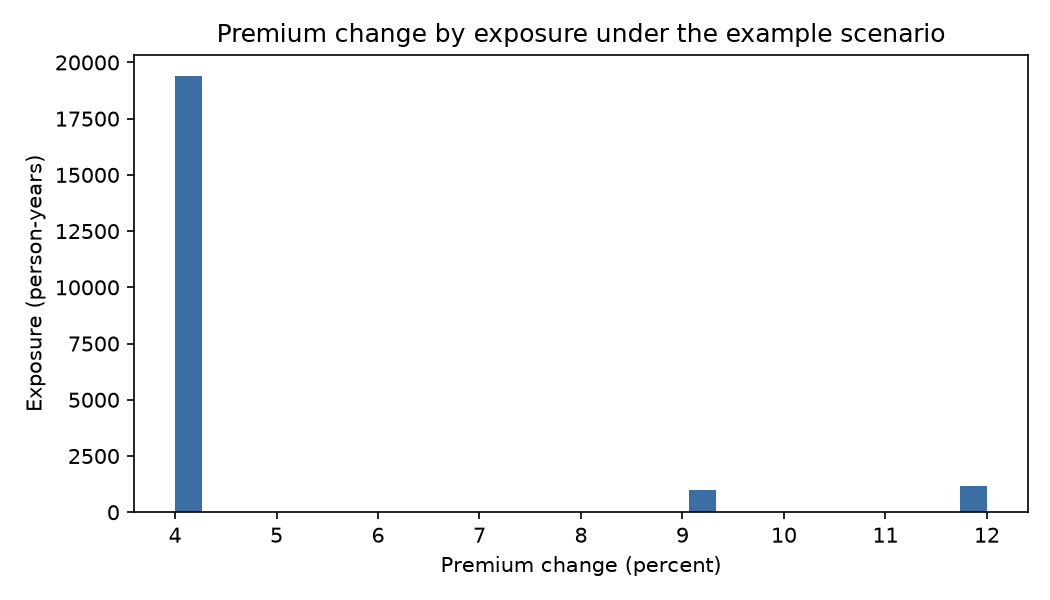

In [12]:
Image(filename=str(tariff_summary.FIGURES_DIR / "scenario_example_dislocation.png"))

## The pound scaling

The scaling sets the model's mean cost per exposure-year at the rating-period level (2,358 dollars) equal to the UK claims cost per
covered life of 576 pounds, which gives 0.244 pounds per dollar. The source is the ABI press release of 6 November 2024 on 2023 data,
with 3.57 billion pounds of PMI claims paid and 6.2 million people covered. The factor includes the exchange rate. The output is a
**risk premium (expected claims cost), illustrative £**. It excludes expenses and margin and is not a UK price. The user chose this
option (option A, all covered lives) at decision gate 8 on 5 November 2026.

## Limitations

- **The 80+ gap.** The rule puts the 80+ tariff 8.2 percent above the technical model on the 2022 test split. The likely cause is the
  exclusion of ER-originated stays, which are concentrated at older ages and pull the model's own older-age curve down. The ER sensitivity
  points the same way but does not settle it.
- **Fitted on 2022.** v1 is fitted on 2022 data with a forecast trend and a credibility-weighted rebase of 1.06. The rebase is a judgement,
  so the 2023 A/E is 1.080 and not 1.00.
- **v2 is deferred.** A pooled refit with a year term, a re-estimated large-claim load and indexed cap, a projection to the rating
  period, the Excel reconciliation and the conversion and elasticity models come after 16 November 2026.
- **Illustrative pounds.** The scaling is a single factor and not a UK price. Older-age relativities would be calibrated to UK market
  experience in a UK implementation.
- **US data.** MEPS is a US survey, so the results show the method.